# Hippocampus segmentation: from data exploration to 3D U-Net training and evaluation

## 1. Project goal

This notebook builds, trains, validates, and tests a small 3D U-Net that segments the hippocampus in 3D MRI scans. It covers data exploration, an intensity-quality investigation, reproducible dataset splitting, in-memory preprocessing, model construction, CPU training, validation-based checkpoint selection, prediction inspection, and final held-out test evaluation.

An MRI volume is a stack of 2D images that forms a 3D view of the brain around the hippocampus. Each voxel stores an MRI signal intensity, not a diagnosis. A segmentation mask uses the same 3D grid and stores an expert label at each voxel: **0** for background, **1** for the anterior hippocampus, and **2** for the posterior hippocampus. The trained model learns to predict these three labels voxel by voxel.

## 2. Dataset source and basic exploration

The data is the official Medical Segmentation Decathlon `Task04_Hippocampus` archive, downloaded from the [MSD AWS downloads page](https://medicaldecathlon.com/dataaws/). The extracted files are expected at `data/Task04_Hippocampus/`.

In [1]:
from collections import Counter
import json
from pathlib import Path

from IPython.display import Markdown, display
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch
import nibabel as nib
import numpy as np

DATASET_DIR = Path("data/Task04_Hippocampus")
assert DATASET_DIR.exists(), f"Dataset not found at {DATASET_DIR.resolve()}"

with (DATASET_DIR / "dataset.json").open() as file:
    dataset_info = json.load(file)

print(f"Dataset: {dataset_info['name']}")
print(f"Modality: {dataset_info['modality']['0']}")
print(f"Declared labeled scans: {dataset_info['numTraining']}")
print(f"Labels: {dataset_info['labels']}")

Dataset: Hippocampus
Modality: MRI
Declared labeled scans: 260
Labels: {'0': 'background', '1': 'Anterior', '2': 'Posterior'}


### File pairing and image properties

Only `imagesTr` has public masks in `labelsTr`, so all analysis and splits use those 260 labeled cases. The official archive also contains hidden macOS `._*` resource-fork files; these are not medical images and are ignored.

In [2]:
def real_nifti_files(folder):
    return sorted(path for path in folder.glob("*.nii.gz") if not path.name.startswith("._"))

image_files = real_nifti_files(DATASET_DIR / "imagesTr")
mask_files = real_nifti_files(DATASET_DIR / "labelsTr")
image_by_name = {path.name: path for path in image_files}
mask_by_name = {path.name: path for path in mask_files}
images_without_masks = sorted(set(image_by_name) - set(mask_by_name))
masks_without_images = sorted(set(mask_by_name) - set(image_by_name))
paired_names = sorted(set(image_by_name) & set(mask_by_name))
pairs = [(image_by_name[name], mask_by_name[name]) for name in paired_names]
scan_ids = [name.removesuffix(".nii.gz") for name in paired_names]

assert len(pairs) == dataset_info["numTraining"] == 260
assert not images_without_masks and not masks_without_images
print(f"MRI scans: {len(image_files)}")
print(f"Masks: {len(mask_files)}")
print(f"Matched pairs: {len(pairs)}")
print(f"Unmatched images: {images_without_masks}")
print(f"Unmatched masks: {masks_without_images}")

MRI scans: 260
Masks: 260
Matched pairs: 260
Unmatched images: []
Unmatched masks: []


In [3]:
scan_stats = {}
all_labels = set()
grid_issues = []
identity_header_values = {field: set() for field in ["descrip", "aux_file", "intent_name"]}

for image_path, mask_path in pairs:
    image_nii = nib.load(image_path)
    mask_nii = nib.load(mask_path)
    image = np.asarray(image_nii.dataobj)
    mask = np.asarray(mask_nii.dataobj)
    scan_id = image_path.name.removesuffix(".nii.gz")
    labels = {int(value) for value in np.unique(mask)}
    all_labels.update(labels)

    if image.shape != mask.shape or not np.allclose(image_nii.affine, mask_nii.affine):
        grid_issues.append(scan_id)

    for field in identity_header_values:
        value = image_nii.header[field].tobytes().rstrip(b"\x00").decode("latin1")
        identity_header_values[field].add(value)

    scan_stats[scan_id] = {
        "shape": tuple(image.shape),
        "spacing_mm": tuple(float(value) for value in image_nii.header.get_zooms()[:3]),
        "minimum": float(image.min()),
        "maximum": float(image.max()),
    }

shape_counts = Counter(row["shape"] for row in scan_stats.values())
spacing_counts = Counter(row["spacing_mm"] for row in scan_stats.values())
dimensions = np.array([row["shape"] for row in scan_stats.values()])

assert not grid_issues
assert all_labels == {0, 1, 2}
print(f"Unique shapes: {len(shape_counts)}")
print(f"Voxel-count range by axis: {dimensions.min(axis=0)} to {dimensions.max(axis=0)}")
print(f"Five most common shapes: {shape_counts.most_common(5)}")
print(f"Voxel spacings in mm: {dict(spacing_counts)}")
print(f"Mask values across all scans: {sorted(all_labels)}")
print(f"Image-mask grid mismatches: {grid_issues}")

Unique shapes: 236
Voxel-count range by axis: [31 40 24] to [43 59 47]
Five most common shapes: [((35, 51, 35), 3), ((35, 51, 36), 3), ((37, 51, 33), 3), ((35, 52, 34), 2), ((38, 52, 33), 2)]
Voxel spacings in mm: {(1.0, 1.0, 1.0): 260}
Mask values across all scans: [0, 1, 2]
Image-mask grid mismatches: []


### Example MRI slices with mask overlays

For each of three scans, the displayed slices are selected from the part of the volume containing a labeled hippocampus. Orange denotes label 1 (anterior) and blue denotes label 2 (posterior).

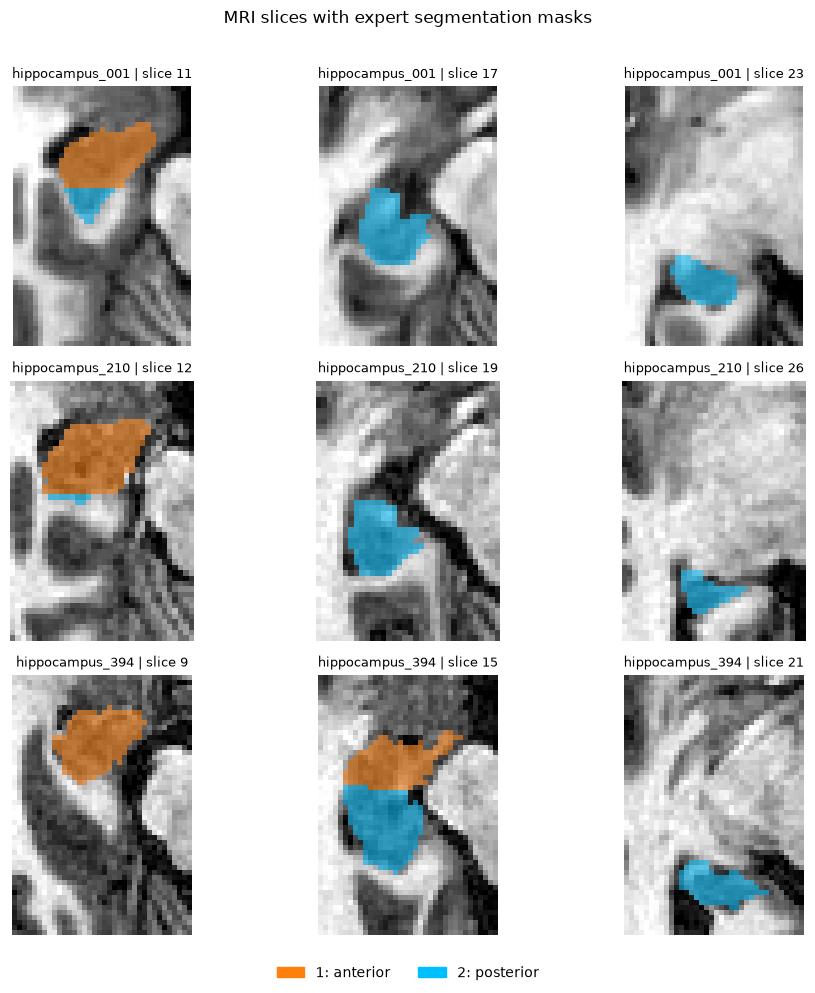

In [4]:
example_indices = [0, len(pairs) // 2, len(pairs) - 1]
example_pairs = [pairs[index] for index in example_indices]
mask_cmap = ListedColormap(["tab:orange", "deepskyblue"])
mask_norm = BoundaryNorm([0.5, 1.5, 2.5], mask_cmap.N)

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for row, (image_path, mask_path) in enumerate(example_pairs):
    image = nib.load(image_path).get_fdata()
    mask = nib.load(mask_path).get_fdata()
    labeled_slices = np.where(np.any(mask > 0, axis=(0, 1)))[0]
    slice_indices = np.quantile(labeled_slices, [0.25, 0.5, 0.75]).astype(int)
    low, high = np.percentile(image, [1, 99])
    for column, slice_index in enumerate(slice_indices):
        axis = axes[row, column]
        axis.imshow(np.rot90(image[:, :, slice_index]), cmap="gray", vmin=low, vmax=high)
        mask_slice = np.ma.masked_equal(np.rot90(mask[:, :, slice_index]), 0)
        axis.imshow(mask_slice, cmap=mask_cmap, norm=mask_norm, alpha=0.55)
        axis.set_title(f"{image_path.name[:-7]} | slice {slice_index}", fontsize=9)
        axis.axis("off")
fig.legend(
    handles=[Patch(color="tab:orange", label="1: anterior"), Patch(color="deepskyblue", label="2: posterior")],
    loc="lower center", ncol=2, frameon=False,
)
fig.suptitle("MRI slices with expert segmentation masks")
fig.tight_layout(rect=(0, 0.04, 1, 0.97))
plt.show()

## 3. Initial intensity finding

MRI intensities do not have a universal unit, so differences between scans are expected. However, a first pass over the full dataset found one maximum that was much larger than the rest. That finding motivated a closer look before making any preprocessing decision.

In [5]:
global_minimum = min(row["minimum"] for row in scan_stats.values())
global_maximum = max(row["maximum"] for row in scan_stats.values())
largest_max_scan = max(scan_stats, key=lambda scan_id: scan_stats[scan_id]["maximum"])
median_scan_maximum = float(np.median([row["maximum"] for row in scan_stats.values()]))

print(f"Scan-wide intensity range: {global_minimum:.1f} to {global_maximum:.1f}")
print(f"Median of the 260 per-scan maxima: {median_scan_maximum:.1f}")
print(f"Largest maximum: {largest_max_scan} ({scan_stats[largest_max_scan]['maximum']:.1f})")

Scan-wide intensity range: 0.0 to 1704295.2
Median of the 260 per-scan maxima: 1948.2
Largest maximum: hippocampus_210 (1704295.2)


`hippocampus_210` reaches roughly 1.7 million while the median per-scan maximum is below 2,000. A maximum alone cannot tell us whether this is anatomy, acquisition scaling, a small artifact, or a damaged file. We therefore inspect its full distribution and spatial location rather than deleting or changing it.

## 4. Outlier investigation

The two comparison scans below are selected reproducibly: their maxima are closest to the dataset's median per-scan maximum. An **extreme voxel** is defined here as a voxel above its scan's 99.9th percentile.

In [6]:
outlier_id = "hippocampus_210"
ordinary_ids = sorted(
    (scan_id for scan_id in scan_ids if scan_id != outlier_id),
    key=lambda scan_id: abs(scan_stats[scan_id]["maximum"] - median_scan_maximum),
)[:2]
comparison_ids = [outlier_id, *ordinary_ids]
comparison_data = {}
distribution_stats = {}

for scan_id in comparison_ids:
    image = nib.load(DATASET_DIR / "imagesTr" / f"{scan_id}.nii.gz").get_fdata()
    mask = nib.load(DATASET_DIR / "labelsTr" / f"{scan_id}.nii.gz").get_fdata()
    comparison_data[scan_id] = (image, mask)
    minimum, p01, median, p99, p999, maximum = np.percentile(image, [0, 1, 50, 99, 99.9, 100])
    distribution_stats[scan_id] = {
        "minimum": float(minimum), "median": float(median), "p01": float(p01),
        "p99": float(p99), "p999": float(p999), "maximum": float(maximum),
        "extreme_count": int(np.sum(image > p999)),
    }

table_lines = [
    "| Scan | Minimum | Median | 1st percentile | 99th percentile | 99.9th percentile | Maximum | Voxels >99.9th |",
    "|---|---:|---:|---:|---:|---:|---:|---:|",
]
for scan_id in comparison_ids:
    row = distribution_stats[scan_id]
    table_lines.append(
        f"| `{scan_id}` | {row['minimum']:.1f} | {row['median']:.1f} | {row['p01']:.1f} | "
        f"{row['p99']:.1f} | {row['p999']:.1f} | {row['maximum']:.1f} | {row['extreme_count']} |"
    )
display(Markdown("\n".join(table_lines)))

| Scan | Minimum | Median | 1st percentile | 99th percentile | 99.9th percentile | Maximum | Voxels >99.9th |
|---|---:|---:|---:|---:|---:|---:|---:|
| `hippocampus_210` | 0.0 | 291440.8 | 25342.7 | 465671.8 | 537648.1 | 1704295.2 | 66 |
| `hippocampus_229` | 0.0 | 470.0 | 43.2 | 805.0 | 869.8 | 1944.9 | 54 |
| `hippocampus_338` | 0.0 | 450.9 | 26.9 | 794.0 | 1370.0 | 1951.5 | 69 |

In [7]:
outlier_image, outlier_mask = comparison_data[outlier_id]
extreme_threshold = distribution_stats[outlier_id]["p999"]
extreme_voxels = outlier_image > extreme_threshold
extreme_coordinates = np.argwhere(extreme_voxels)
segmentation_coordinates = np.argwhere(outlier_mask > 0)
maximum_coordinate = np.array(np.unravel_index(np.argmax(outlier_image), outlier_image.shape))
distance_to_edge = np.minimum(
    extreme_coordinates, np.array(outlier_image.shape) - 1 - extreme_coordinates
).min(axis=1)
squared_distances = ((extreme_coordinates[:, None, :] - segmentation_coordinates[None, :, :]) ** 2).sum(axis=2)
nearest_segmentation_distance = float(np.sqrt(squared_distances.min(axis=1)).min())

print(f"Image shape: {outlier_image.shape}")
print(f"99.9th-percentile threshold: {extreme_threshold:.1f}")
print(f"Extreme voxels: {extreme_voxels.sum()} of {outlier_image.size} ({100 * extreme_voxels.mean():.3f}%)")
print(f"Voxels above 1,000,000: {np.sum(outlier_image > 1_000_000)}")
print(f"Extreme bounding box: {extreme_coordinates.min(axis=0)} to {extreme_coordinates.max(axis=0)}")
print(f"Segmentation bounding box: {segmentation_coordinates.min(axis=0)} to {segmentation_coordinates.max(axis=0)}")
print(f"Maximum coordinate: {maximum_coordinate}; label there: {int(outlier_mask[tuple(maximum_coordinate)])}")
print(f"Extreme voxels inside the segmentation: {np.sum(extreme_voxels & (outlier_mask > 0))}")
print(f"Extreme voxels on the outer boundary: {np.sum(distance_to_edge == 0)}")
print(f"Extreme voxels within 5 voxels of an edge: {np.sum(distance_to_edge <= 5)}")
print(f"Nearest extreme voxel to the segmentation: {nearest_segmentation_distance:.1f} voxels")

Image shape: (34, 48, 40)
99.9th-percentile threshold: 537648.1
Extreme voxels: 66 of 65280 (0.101%)
Voxels above 1,000,000: 28
Extreme bounding box: [25 30  0] to [33 47  5]
Segmentation bounding box: [5 4 6] to [27 42 33]
Maximum coordinate: [30 47  3]; label there: 0
Extreme voxels inside the segmentation: 0
Extreme voxels on the outer boundary: 40
Extreme voxels within 5 voxels of an edge: 66
Nearest extreme voxel to the segmentation: 9.5 voxels


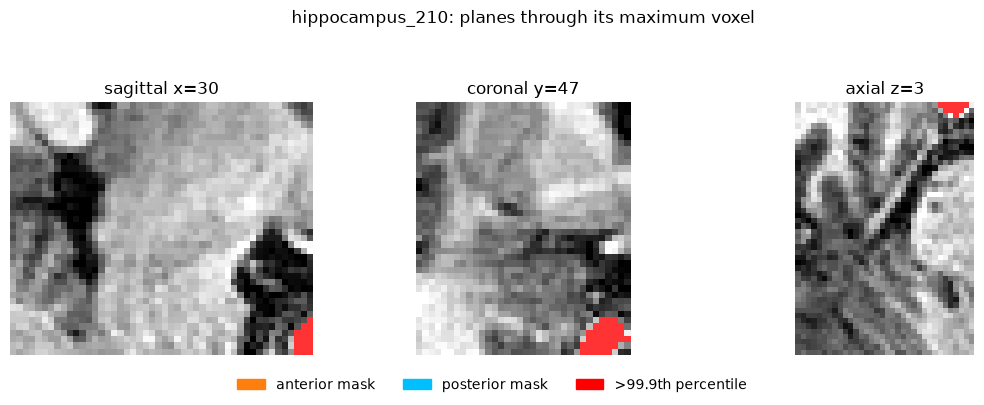

In [8]:
x, y, z = maximum_coordinate
planes = [
    (outlier_image[x, :, :], outlier_mask[x, :, :], extreme_voxels[x, :, :], f"sagittal x={x}"),
    (outlier_image[:, y, :], outlier_mask[:, y, :], extreme_voxels[:, y, :], f"coronal y={y}"),
    (outlier_image[:, :, z], outlier_mask[:, :, z], extreme_voxels[:, :, z], f"axial z={z}"),
]
low, high = np.percentile(outlier_image, [1, 99])
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
for axis, (image_plane, mask_plane, extreme_plane, title) in zip(axes, planes):
    axis.imshow(np.rot90(image_plane), cmap="gray", vmin=low, vmax=high)
    axis.imshow(np.ma.masked_equal(np.rot90(mask_plane), 0), cmap=mask_cmap, norm=mask_norm, alpha=0.5)
    axis.imshow(
        np.ma.masked_equal(np.rot90(extreme_plane), False),
        cmap=ListedColormap(["red"]), alpha=0.8,
    )
    axis.set_title(title)
    axis.axis("off")
fig.legend(
    handles=[
        Patch(color="tab:orange", label="anterior mask"),
        Patch(color="deepskyblue", label="posterior mask"),
        Patch(color="red", label=">99.9th percentile"),
    ],
    loc="lower center", ncol=3, frameon=False,
)
fig.suptitle("hippocampus_210: planes through its maximum voxel")
fig.tight_layout(rect=(0, 0.08, 1, 0.92))
plt.show()

### Interpretation and limits of the evidence

The unusually high median shows that `hippocampus_210` differs in scale across the scan, not only at one voxel. Its brightest 66 voxels are all near an image boundary, none is inside the mask, and the closest is 9.5 voxels from the segmentation. This supports the practical interpretation of a scan-scale difference plus a bright boundary artifact rather than hippocampus anatomy.

It does **not** prove the acquisition cause, establish that the scan is clinically defective, or justify deleting it. We would need acquisition metadata or expert review for those conclusions. Robust per-volume normalization is therefore worth testing, possibly with percentile clipping. The normalization **policy** is chosen using training and validation cases, while its percentiles are computed separately from each input image—including future unseen images—without using a segmentation mask. The original NIfTI files remain unchanged.

## 5. Reproducible train/validation/test split

Training cases are used to fit model parameters. Validation cases are kept separate for choices such as preprocessing settings and model selection. Test cases are held back for a final, less biased estimate of performance. The 182/39/39 allocation is exactly 70%/15%/15% of the 260 labeled cases.

A fixed random seed makes the random assignment reproducible: anyone running the notebook with the same scan IDs and seed will obtain the same groups. The next cell starts from all 260 sorted scan IDs, shuffles them with NumPy seed 42, assigns them to the three sets, and saves the IDs, seed, and counts to `splits.json`. As a rerun safeguard, if that file is already present, the cell verifies that it exactly matches the split it just produced instead of silently replacing it.

In [9]:
SEED = 42
rng = np.random.default_rng(SEED)
shuffled_ids = np.array(scan_ids)
rng.shuffle(shuffled_ids)
splits = {
    "train": sorted(shuffled_ids[:182].tolist()),
    "validation": sorted(shuffled_ids[182:221].tolist()),
    "test": sorted(shuffled_ids[221:].tolist()),
}
split_sets = {name: set(ids) for name, ids in splits.items()}
counts = {name: len(ids) for name, ids in splits.items()}
overlaps = {
    "train/validation": len(split_sets["train"] & split_sets["validation"]),
    "train/test": len(split_sets["train"] & split_sets["test"]),
    "validation/test": len(split_sets["validation"] & split_sets["test"]),
}

assert counts == {"train": 182, "validation": 39, "test": 39}
assert all(count == 0 for count in overlaps.values())
assert set().union(*split_sets.values()) == set(scan_ids)
assert sum(counts.values()) == len(scan_ids)

split_manifest = {
    "dataset": "Medical Segmentation Decathlon Task04_Hippocampus",
    "seed": SEED,
    "identity_basis": (
        "Scan filename only. dataset.json and the standard NIfTI free-text header fields provide no "
        "patient identifiers, so patient-level identity could not be verified."
    ),
    "counts": counts,
    "splits": splits,
}
split_path = Path("splits.json")
if split_path.exists():
    with split_path.open() as file:
        saved_manifest = json.load(file)
    assert saved_manifest == split_manifest, "splits.json does not match the seed-42 split"
    manifest_result = "splits.json was present and matches the generated split"
else:
    with split_path.open("w") as file:
        json.dump(split_manifest, file, indent=2)
        file.write("\n")
    manifest_result = "Created splits.json"

print(f"Seed: {SEED}")
print(f"Counts: {counts}")
print(f"Pairwise overlaps: {overlaps}")
print("Coverage: every labeled scan appears exactly once")
print(manifest_result)

Seed: 42
Counts: {'train': 182, 'validation': 39, 'test': 39}
Pairwise overlaps: {'train/validation': 0, 'train/test': 0, 'validation/test': 0}
Coverage: every labeled scan appears exactly once
splits.json was present and matches the generated split


In [10]:
metadata_fields = set(dataset_info["training"][0])
readable_header_values = {field: sorted(values) for field, values in identity_header_values.items()}
print(f"Training-item metadata fields: {sorted(metadata_fields)}")
print(f"NIfTI identity-related header values: {readable_header_values}")
print("Patient-level identity could not be verified; scan filenames are the only available split unit.")

Training-item metadata fields: ['image', 'label']
NIfTI identity-related header values: {'descrip': ['5.0.10'], 'aux_file': ['none'], 'intent_name': ['']}
Patient-level identity could not be verified; scan filenames are the only available split unit.


## 6. Intensity preprocessing

MRI signal scales vary substantially between scans, so a model should not have to interpret the same tissue at completely different numeric scales. The small function below calculates the 1st and 99th percentiles from **nonzero voxels in one image**, clips that image to those bounds, and linearly scales the result to `[0, 1]`. Zero-valued background stays zero, and the segmentation mask is never used to calculate normalization values.

If an image has no nonzero voxels, or if its two percentile bounds are equal, the function safely returns an all-zero `float32` volume. This avoids division by zero. Processing happens only in memory and does not alter any NIfTI file.

In [11]:
def normalize_mri_intensity(volume):
    """Clip nonzero voxels to their 1st–99th percentiles and scale to [0, 1]."""
    volume = np.asarray(volume)
    normalized = np.zeros(volume.shape, dtype=np.float32)
    nonzero = volume != 0

    if not np.any(nonzero):
        return normalized

    lower, upper = np.percentile(volume[nonzero], [1, 99])
    if not np.isfinite(lower) or not np.isfinite(upper) or upper <= lower:
        return normalized

    clipped = np.clip(volume[nonzero], lower, upper)
    normalized[nonzero] = ((clipped - lower) / (upper - lower)).astype(np.float32)
    return normalized

# Explicit checks for the two edge cases.
assert np.array_equal(normalize_mri_intensity(np.zeros((2, 2))), np.zeros((2, 2), dtype=np.float32))
assert np.array_equal(normalize_mri_intensity(np.full((2, 2), 7.0)), np.zeros((2, 2), dtype=np.float32))

### Apply it to three training scans

`hippocampus_210` belongs to the training set. For a fair comparison, the two ordinary scans are also selected only from training: they are the scans whose raw maxima are closest to the median maximum among training scans.

In [12]:
training_ids = splits["train"]
assert outlier_id in training_ids
training_median_maximum = float(np.median([scan_stats[scan_id]["maximum"] for scan_id in training_ids]))
ordinary_training_ids = sorted(
    (scan_id for scan_id in training_ids if scan_id != outlier_id),
    key=lambda scan_id: abs(scan_stats[scan_id]["maximum"] - training_median_maximum),
)[:2]
preprocessing_ids = [outlier_id, *ordinary_training_ids]
preprocessing_cases = {}
preprocessing_stats = {}

for scan_id in preprocessing_ids:
    image = nib.load(DATASET_DIR / "imagesTr" / f"{scan_id}.nii.gz").get_fdata()
    mask = nib.load(DATASET_DIR / "labelsTr" / f"{scan_id}.nii.gz").get_fdata()
    normalized = normalize_mri_intensity(image)
    nonzero_values = image[image != 0]
    lower, upper = np.percentile(nonzero_values, [1, 99])
    preprocessing_cases[scan_id] = (image, normalized, mask)
    preprocessing_stats[scan_id] = {
        "raw_min": float(image.min()),
        "raw_median": float(np.median(nonzero_values)),
        "raw_max": float(image.max()),
        "lower": float(lower),
        "upper": float(upper),
        "normalized_min": float(normalized.min()),
        "normalized_max": float(normalized.max()),
        "clipped_low": int(np.sum(nonzero_values < lower)),
        "clipped_high": int(np.sum(nonzero_values > upper)),
    }

    assert normalized.shape == image.shape
    assert normalized.dtype == np.float32
    assert normalized.min() >= 0.0 and normalized.max() <= 1.0
    assert np.all(normalized[image == 0] == 0.0)
    assert set(np.unique(mask).astype(int)) == {0, 1, 2}

table_lines = [
    "| Training scan | Raw min | Raw nonzero median | Raw max | Nonzero P1 | Nonzero P99 | After min–max | Clipped low/high |",
    "|---|---:|---:|---:|---:|---:|---:|---:|",
]
for scan_id in preprocessing_ids:
    row = preprocessing_stats[scan_id]
    table_lines.append(
        f"| `{scan_id}` | {row['raw_min']:.1f} | {row['raw_median']:.1f} | {row['raw_max']:.1f} | "
        f"{row['lower']:.1f} | {row['upper']:.1f} | "
        f"{row['normalized_min']:.1f}–{row['normalized_max']:.1f} | "
        f"{row['clipped_low']}/{row['clipped_high']} |"
    )
display(Markdown("\n".join(table_lines)))
print(f"Training scans compared: {preprocessing_ids}")
print("Checks passed: shapes unchanged, float32 values in [0, 1], background zero, masks still {0, 1, 2}.")

| Training scan | Raw min | Raw nonzero median | Raw max | Nonzero P1 | Nonzero P99 | After min–max | Clipped low/high |
|---|---:|---:|---:|---:|---:|---:|---:|
| `hippocampus_210` | 0.0 | 291440.8 | 1704295.2 | 25342.7 | 465671.8 | 0.0–1.0 | 552/579 |
| `hippocampus_249` | 0.0 | 588.6 | 1942.4 | 51.5 | 1125.7 | 0.0–1.0 | 507/541 |
| `hippocampus_295` | 0.0 | 471.3 | 1942.5 | 42.8 | 821.3 | 0.0–1.0 | 563/496 |

Training scans compared: ['hippocampus_210', 'hippocampus_249', 'hippocampus_295']
Checks passed: shapes unchanged, float32 values in [0, 1], background zero, masks still {0, 1, 2}.


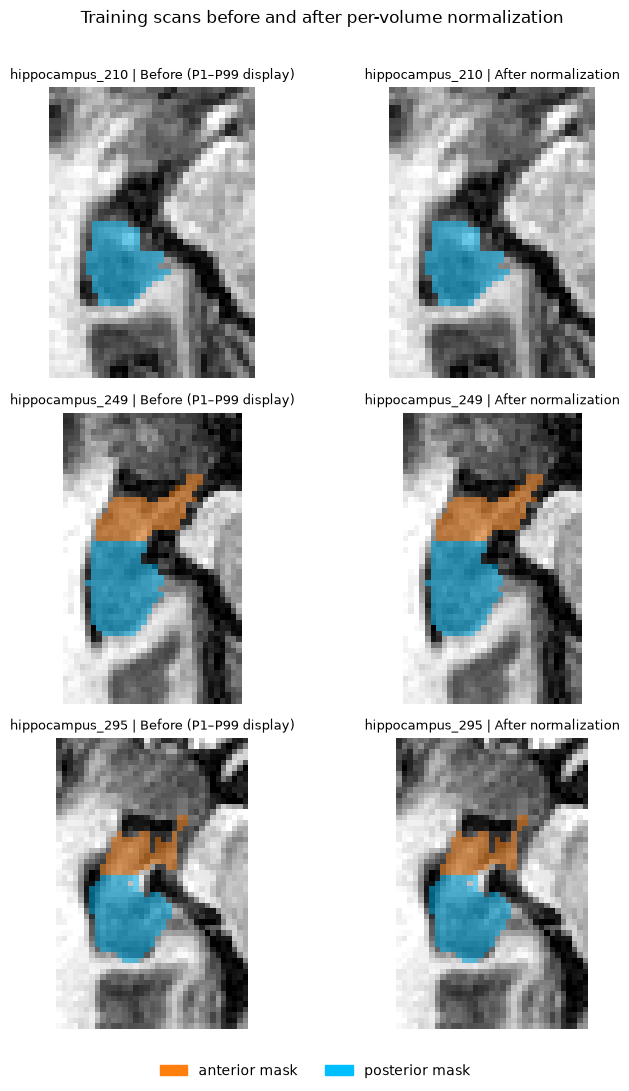

In [13]:
fig, axes = plt.subplots(3, 2, figsize=(8, 11))
for row, scan_id in enumerate(preprocessing_ids):
    image, normalized, mask = preprocessing_cases[scan_id]
    labeled_slices = np.where(np.any(mask > 0, axis=(0, 1)))[0]
    slice_index = int(np.median(labeled_slices))
    mask_slice = np.ma.masked_equal(np.rot90(mask[:, :, slice_index]), 0)
    lower = preprocessing_stats[scan_id]["lower"]
    upper = preprocessing_stats[scan_id]["upper"]

    axes[row, 0].imshow(np.rot90(image[:, :, slice_index]), cmap="gray", vmin=lower, vmax=upper)
    axes[row, 1].imshow(np.rot90(normalized[:, :, slice_index]), cmap="gray", vmin=0, vmax=1)
    for column, title in enumerate(["Before (P1–P99 display)", "After normalization"]):
        axes[row, column].imshow(mask_slice, cmap=mask_cmap, norm=mask_norm, alpha=0.5)
        axes[row, column].set_title(f"{scan_id} | {title}", fontsize=9)
        axes[row, column].axis("off")

fig.legend(
    handles=[Patch(color="tab:orange", label="anterior mask"), Patch(color="deepskyblue", label="posterior mask")],
    loc="lower center", ncol=2, frameon=False,
)
fig.suptitle("Training scans before and after per-volume normalization")
fig.tight_layout(rect=(0, 0.04, 1, 0.97))
plt.show()

### What changed?

Clipping maps the lowest 1% of nonzero intensities to 0 and the highest 1% to 1; the central 98% is scaled linearly. This prevents the bright boundary tail in `hippocampus_210` from controlling the entire numeric range and places all three scans on a consistent `[0, 1]` scale. Background remains zero and mask data is untouched.

The before panels use each raw image's P1–P99 values as their display limits, while the normalized panels display 0–1. Those are equivalent mappings for the central intensity range, so their visual similarity is expected. It confirms that the displayed anatomy and mask remain spatially aligned, but it does **not** prove that clipping preserves all useful information. The table therefore keeps the counts of low- and high-tail voxels collapsed by clipping. Some tail differences could be meaningful, and selected slices may not show them, so we cannot conclude from this figure alone that no useful detail is lost. The policy should be assessed across training cases and chosen with validation performance—not tuned on test cases. Once fixed, the 1st and 99th percentiles are calculated independently for every input volume, including future unseen images.

### Section 6 conclusion

The notebook now explores the data, investigates the outlier, creates the fixed split, and demonstrates an in-memory intensity preprocessing function. It does not overwrite source images, use masks for normalization, or train a model.

## 7. Handling different volume shapes

A training batch is usually one rectangular array with dimensions such as `(batch, channels, x, y, z)`. The individual volumes therefore need equal spatial shapes before they can be stacked: NumPy and deep-learning libraries cannot form one regular batch from arrays whose axes have different lengths.

We use a fixed target shape of **`(48, 64, 48)`**, which is large enough for the dimensions observed during exploration. This section checks shapes for every split, but it only loads and pads the same three **training** examples used in Section 6. Validation and test images and masks are not processed in this demonstration.

In [14]:
TARGET_SHAPE = (48, 64, 48)
all_observed_shapes = np.array([scan_stats[scan_id]["shape"] for scan_id in scan_ids])
largest_observed_shape = tuple(int(value) for value in all_observed_shapes.max(axis=0))

assert np.all(np.array(largest_observed_shape) <= np.array(TARGET_SHAPE))
print(f"Largest observed shape per axis: {largest_observed_shape}")
print(f"Target shape: {TARGET_SHAPE}")
print("Every labeled scan fits inside the target shape.")

# Shape-only checks: no validation or test image/mask is loaded or padded here.
for split_name in ["validation", "test"]:
    split_shapes = np.array([scan_stats[scan_id]["shape"] for scan_id in splits[split_name]])
    split_largest = tuple(int(value) for value in split_shapes.max(axis=0))
    assert np.all(split_shapes <= np.array(TARGET_SHAPE))
    print(f"{split_name.capitalize()} shape check only — largest: {split_largest}; all fit: True")

Largest observed shape per axis: (43, 59, 47)
Target shape: (48, 64, 48)
Every labeled scan fits inside the target shape.
Validation shape check only — largest: (39, 58, 43); all fit: True
Test shape check only — largest: (41, 59, 42); all fit: True


### Symmetric zero-padding

The function below pads the normalized image and its mask with the same zero widths. It divides the required padding between both ends of each axis; when an odd number of voxels is needed, the second end receives the one extra voxel. It returns three slices that record exactly where the original arrays were placed. It never resizes, interpolates, or crops.

In [15]:
def pad_image_and_mask(image, mask, target_shape=TARGET_SHAPE):
    """Zero-pad one 3D image and mask together, returning their placement slices."""
    image = np.asarray(image)
    mask = np.asarray(mask)
    if image.ndim != 3 or mask.ndim != 3 or image.shape != mask.shape:
        raise ValueError(f"Image and mask must be matching 3D arrays; got {image.shape} and {mask.shape}.")

    missing = np.array(target_shape) - np.array(image.shape)
    if np.any(missing < 0):
        raise ValueError(f"Input shape {image.shape} is too large for target shape {target_shape}.")

    before = missing // 2
    after = missing - before
    pad_width = tuple((int(left), int(right)) for left, right in zip(before, after))
    placement = tuple(slice(int(left), int(left + size)) for left, size in zip(before, image.shape))
    padded_image = np.pad(image, pad_width, mode="constant", constant_values=0)
    padded_mask = np.pad(mask, pad_width, mode="constant", constant_values=0)
    return padded_image, padded_mask, placement


In [16]:
padded_training_cases = {}
for scan_id in preprocessing_ids:
    _, normalized, mask = preprocessing_cases[scan_id]
    padded_image, padded_mask, placement = pad_image_and_mask(normalized, mask)

    assert padded_image.shape == TARGET_SHAPE
    assert padded_mask.shape == TARGET_SHAPE
    assert padded_image.min() >= 0.0 and padded_image.max() <= 1.0
    assert set(np.unique(padded_mask).astype(int)) == {0, 1, 2}
    assert np.array_equal(padded_image[placement], normalized)
    assert np.array_equal(padded_mask[placement], mask)

    padding_region = np.ones(TARGET_SHAPE, dtype=bool)
    padding_region[placement] = False
    assert np.all(padded_image[padding_region] == 0)
    assert np.all(padded_mask[padding_region] == 0)

    padded_training_cases[scan_id] = (padded_image, padded_mask, placement)
    print(f"{scan_id}: {normalized.shape} -> {padded_image.shape}; placement={placement}")

print("Checks passed: shared padding, valid values and labels, and exact recovery for all three training scans.")

hippocampus_210: (34, 48, 40) -> (48, 64, 48); placement=(slice(7, 41, None), slice(8, 56, None), slice(4, 44, None))
hippocampus_249: (32, 52, 34) -> (48, 64, 48); placement=(slice(8, 40, None), slice(6, 58, None), slice(7, 41, None))
hippocampus_295: (35, 53, 36) -> (48, 64, 48); placement=(slice(6, 41, None), slice(5, 58, None), slice(6, 42, None))
Checks passed: shared padding, valid values and labels, and exact recovery for all three training scans.


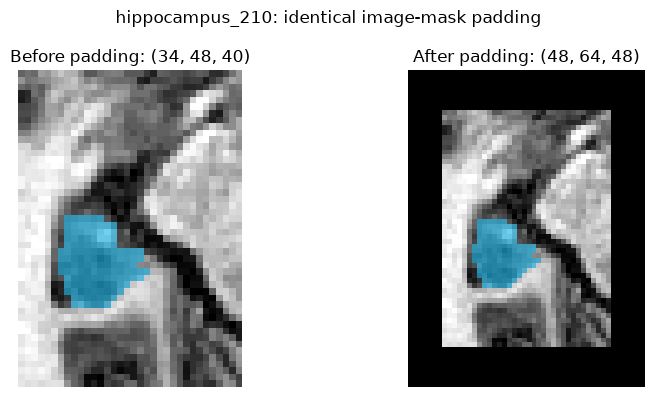

In [17]:
example_id = preprocessing_ids[0]
_, normalized, mask = preprocessing_cases[example_id]
padded_image, padded_mask, placement = padded_training_cases[example_id]
original_slice = int(np.median(np.where(np.any(mask > 0, axis=(0, 1)))[0]))
padded_slice = placement[2].start + original_slice

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(np.rot90(normalized[:, :, original_slice]), cmap="gray", vmin=0, vmax=1)
axes[0].imshow(
    np.ma.masked_equal(np.rot90(mask[:, :, original_slice]), 0),
    cmap=mask_cmap, norm=mask_norm, alpha=0.5,
)
axes[0].set_title(f"Before padding: {normalized.shape}")

axes[1].imshow(np.rot90(padded_image[:, :, padded_slice]), cmap="gray", vmin=0, vmax=1)
axes[1].imshow(
    np.ma.masked_equal(np.rot90(padded_mask[:, :, padded_slice]), 0),
    cmap=mask_cmap, norm=mask_norm, alpha=0.5,
)
axes[1].set_title(f"After padding: {padded_image.shape}")
for axis in axes:
    axis.axis("off")
fig.suptitle(f"{example_id}: identical image-mask padding")
fig.tight_layout()
plt.show()

### What padding changes

Padding changes the array coordinates because the original volume is shifted away from index zero into the larger grid. It does **not** change any original voxel value, segmentation label, or voxel spacing; it only adds zero-valued borders in memory. The returned placement slices preserve that coordinate mapping and will be needed to remove padding from future model predictions before comparing them with an original-size mask or saving them in the original image space. The source NIfTI files remain untouched.

### Section 7 conclusion

All 260 labeled volumes fit the fixed target shape, and the three training demonstrations pass shape, range, label, shared-padding, and exact-recovery checks. Validation and test cases were checked only through their previously collected shape metadata. No model has been trained.

## 8. Preparing batches for a model

A PyTorch `Dataset` describes how to load one example. It stores only the requested scan IDs and loads a NIfTI image and mask **on demand** in `__getitem__`, so the 260 volumes are not kept in memory. Each image is normalized and then padded together with its mask by the functions defined above.

The returned image shape is `(1, 48, 64, 48)`. Its leading dimension is the **channel** dimension; it is 1 because this task has one MRI modality. A `DataLoader` adds the batch dimension, producing `(batch, channels, x, y, z)`. Masks do not contain continuous MRI intensities: every voxel is a categorical class ID—0, 1, or 2—so masks remain integer `int64` tensors and are never intensity-normalized. The dataset also returns a Boolean `valid_region`: it is true throughout the original scan and false only in the artificial padding. Genuine background inside the original scan therefore remains valid.

In [18]:
import torch
from torch.utils.data import DataLoader, Dataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Selected device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(device)}")


class HippocampusDataset(Dataset):
    def __init__(self, scan_ids, dataset_dir=DATASET_DIR, target_shape=TARGET_SHAPE):
        self.scan_ids = list(scan_ids)
        self.dataset_dir = Path(dataset_dir)
        self.target_shape = target_shape

    def __len__(self):
        return len(self.scan_ids)

    def __getitem__(self, index):
        scan_id = self.scan_ids[index]
        image = nib.load(self.dataset_dir / "imagesTr" / f"{scan_id}.nii.gz").get_fdata()
        mask = nib.load(self.dataset_dir / "labelsTr" / f"{scan_id}.nii.gz").get_fdata()
        normalized = normalize_mri_intensity(image)
        padded_image, padded_mask, placement = pad_image_and_mask(normalized, mask, self.target_shape)
        valid_region = np.zeros(self.target_shape, dtype=bool)
        valid_region[placement] = True

        image_tensor = torch.from_numpy(padded_image).unsqueeze(0).to(torch.float32)
        mask_tensor = torch.from_numpy(padded_mask.astype(np.int64))
        valid_region_tensor = torch.from_numpy(valid_region)
        return {
            "image": image_tensor, "mask": mask_tensor,
            "valid_region": valid_region_tensor, "scan_id": scan_id,
        }


Selected device: cuda
GPU: NVIDIA GeForce GTX 1650 Ti


### Create training and validation datasets and inspect one batch

Only the training loader is created here. It shuffles examples and uses `num_workers=0`, which keeps loading simple and notebook-friendly. We retrieve exactly one batch to verify the data interface; the test split is left untouched.

In [19]:
training_dataset = HippocampusDataset(splits["train"])
validation_dataset = HippocampusDataset(splits["validation"])
assert len(training_dataset) == 182 and len(validation_dataset) == 39

loader_generator = torch.Generator().manual_seed(SEED)
training_loader = DataLoader(
    training_dataset, batch_size=2, shuffle=True, num_workers=0, generator=loader_generator
)
batch = next(iter(training_loader))
images = batch["image"]
masks = batch["mask"]
valid_regions = batch["valid_region"]
batch_scan_ids = list(batch["scan_id"])
mask_labels = torch.unique(masks).tolist()

assert images.shape == (2, 1, *TARGET_SHAPE)
assert masks.shape == (2, *TARGET_SHAPE)
assert valid_regions.shape == (2, *TARGET_SHAPE)
assert images.dtype == torch.float32
assert masks.dtype == torch.int64
assert valid_regions.dtype == torch.bool
assert float(images.min()) >= 0.0 and float(images.max()) <= 1.0
assert mask_labels == [0, 1, 2]
assert all(scan_id in splits["train"] for scan_id in batch_scan_ids)

print(f"Image batch shape: {tuple(images.shape)}; dtype: {images.dtype}")
print(f"Mask batch shape: {tuple(masks.shape)}; dtype: {masks.dtype}")
print(f"Valid-region shape: {tuple(valid_regions.shape)}; dtype: {valid_regions.dtype}")
print(f"Scan IDs: {batch_scan_ids}")
print(f"Image range: {float(images.min()):.1f} to {float(images.max()):.1f}")
print(f"Mask labels: {mask_labels}")
print("One training batch verified.")

Image batch shape: (2, 1, 48, 64, 48); dtype: torch.float32
Mask batch shape: (2, 48, 64, 48); dtype: torch.int64
Valid-region shape: (2, 48, 64, 48); dtype: torch.bool
Scan IDs: ['hippocampus_094', 'hippocampus_259']
Image range: 0.0 to 1.0
Mask labels: [0, 1, 2]
One training batch verified.


### Section 8 conclusion

Training and validation datasets now expose consistently normalized and padded tensors while loading scans only when requested. The single inspected batch satisfies the expected shapes, dtypes, ranges, labels, and training-split membership. The test split was not accessed, and no augmentation, caching, loss function, model, or training loop has been added.

## 9. A small 3D U-Net baseline

A 3D U-Net processes the full three-dimensional grid. Its input has **one channel** because each example contains one MRI modality. Its final layer has **three output channels**, one for each class: background, anterior hippocampus, and posterior hippocampus.

At every voxel, those three output numbers are **logits**: unrestricted raw class scores. They are not normalized intensities, probabilities, or final labels. A trained model would learn to make the correct class score largest at each voxel, but the randomly initialized model below has not learned anything yet.

### Reusable convolution block

Each block applies two small 3D convolutions followed by ReLU activations. Padding keeps the spatial shape unchanged within a block.

In [20]:
from torch import nn


class ConvBlock3D(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv3d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.layers(x)


### Two downsampling stages with skip connections

The encoder uses two max-pooling operations to learn increasingly coarse features. The decoder upsamples twice. At each level, a **skip connection** concatenates encoder features with decoder features at the same spatial resolution, helping the network retain fine location information. A small base width of 8 channels keeps this baseline compact.

In [21]:
class SmallUNet3D(nn.Module):
    def __init__(self, in_channels=1, num_classes=3, base_channels=8):
        super().__init__()
        self.encoder1 = ConvBlock3D(in_channels, base_channels)
        self.encoder2 = ConvBlock3D(base_channels, base_channels * 2)
        self.bottleneck = ConvBlock3D(base_channels * 2, base_channels * 4)
        self.pool = nn.MaxPool3d(kernel_size=2, stride=2)

        self.up2 = nn.ConvTranspose3d(base_channels * 4, base_channels * 2, kernel_size=2, stride=2)
        self.decoder2 = ConvBlock3D(base_channels * 4, base_channels * 2)
        self.up1 = nn.ConvTranspose3d(base_channels * 2, base_channels, kernel_size=2, stride=2)
        self.decoder1 = ConvBlock3D(base_channels * 2, base_channels)
        self.output_layer = nn.Conv3d(base_channels, num_classes, kernel_size=1)

    def forward(self, x):
        skip1 = self.encoder1(x)
        skip2 = self.encoder2(self.pool(skip1))
        x = self.bottleneck(self.pool(skip2))
        x = self.decoder2(torch.cat([self.up2(x), skip2], dim=1))
        x = self.decoder1(torch.cat([self.up1(x), skip1], dim=1))
        return self.output_layer(x)


### One untrained forward pass

We set a seed immediately before model initialization, move the model and batch to the selected `device`, disable gradient tracking, and run exactly one forward pass using the batch from Section 8. This checks only that the tensor interface is correct.

In [22]:
MODEL_SEED = 42
torch.manual_seed(MODEL_SEED)
model = SmallUNet3D(in_channels=1, num_classes=3, base_channels=8).to(device)
parameter_count = sum(parameter.numel() for parameter in model.parameters())

model.eval()
with torch.no_grad():
    logits = model(images.to(device))

assert logits.shape == (2, 3, 48, 64, 48)
assert torch.isfinite(logits).all()
print(f"Model parameters: {parameter_count:,}")
print(f"Output logits shape: {tuple(logits.shape)}")
print(f"All logits are finite. One {device.type.upper()} forward pass completed without gradient tracking.")

Model parameters: 85,035
Output logits shape: (2, 3, 48, 64, 48)
All logits are finite. One CUDA forward pass completed without gradient tracking.


### Important limitation

These logits have **no segmentation value yet**. The model is randomly initialized and has never been trained, so its output must not be interpreted as a hippocampus prediction. This section only verifies the architecture's dimensions and numerical execution; it does not calculate a loss, convert logits into predictions, evaluate performance, or update any parameter.

## 10. Loss and one training-step check

Cross-entropy compares the model's three logits at each voxel with the mask's integer class ID. The logits go directly into PyTorch cross-entropy—no softmax is applied first—because the operation combines the required log-softmax and negative log-likelihood in a numerically stable way. The target mask must contain integer IDs `0`, `1`, and `2`, which select the correct class score at each voxel.

We request `reduction="none"` to keep one loss value per voxel. We then average only where `valid_region` is true. This excludes the artificial padded border while retaining genuine class-0 background inside each original scan.

### One optimization step on the selected device

The cell below creates a **fresh** model with seed 42, performs one forward pass on the same training batch, computes the valid-region loss, backpropagates once, and makes one Adam update. We check finite loss and gradients and confirm that at least one parameter changed. We do not require the loss to decrease after one step; a single stochastic update does not guarantee that.

In [23]:
TRAINING_STEP_SEED = 42
torch.manual_seed(TRAINING_STEP_SEED)
if device.type == "cuda":
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats(device)
training_step_model = SmallUNet3D(in_channels=1, num_classes=3, base_channels=8).to(device)
optimizer = torch.optim.Adam(training_step_model.parameters(), lr=1e-3)
parameters_before = [parameter.detach().cpu().clone() for parameter in training_step_model.parameters()]

training_step_model.train()
optimizer.zero_grad()
batch_images = images.to(device)
batch_masks = masks.to(device)
valid_on_device = valid_regions.to(device)
step_logits = training_step_model(batch_images)
per_voxel_loss = nn.functional.cross_entropy(step_logits, batch_masks, reduction="none")
loss = per_voxel_loss[valid_on_device].mean()

assert torch.isfinite(loss)
loss.backward()
gradients = [parameter.grad for parameter in training_step_model.parameters() if parameter.grad is not None]
assert gradients and all(torch.isfinite(gradient).all() for gradient in gradients)
optimizer.step()

changed_parameters = sum(
    not torch.equal(before, after.detach().cpu())
    for before, after in zip(parameters_before, training_step_model.parameters())
)
assert changed_parameters > 0
valid_voxels = int(valid_on_device.sum())
padded_voxels = int(valid_on_device.numel() - valid_voxels)
if device.type == "cuda":
    torch.cuda.synchronize(device)
    peak_allocated_mib = torch.cuda.max_memory_allocated(device) / 1024**2
    peak_reserved_mib = torch.cuda.max_memory_reserved(device) / 1024**2

print(f"Masked cross-entropy loss: {float(loss.detach()):.6f}")
print(f"Valid voxels: {valid_voxels:,}; padded voxels excluded: {padded_voxels:,}")
print(f"Parameter tensors changed: {changed_parameters}")
print(f"Loss and gradients are finite; one {device.type.upper()} Adam step completed.")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(device)}")
    print(f"Peak allocated GPU memory: {peak_allocated_mib:.1f} MiB")
    print(f"Peak reserved GPU memory: {peak_reserved_mib:.1f} MiB")

Masked cross-entropy loss: 1.252476
Valid voxels: 119,324; padded voxels excluded: 175,588
Parameter tensors changed: 26
Loss and gradients are finite; one CUDA Adam step completed.
GPU: NVIDIA GeForce GTX 1650 Ti
Peak allocated GPU memory: 104.8 MiB
Peak reserved GPU memory: 126.0 MiB


### What this check establishes

This single update verifies the training mechanics: batch loading, valid-region masking, logits and target compatibility, gradient flow, and parameter updating. It does **not** establish segmentation performance, convergence, or generalization. No validation or test data was used, no Dice loss was added, and the model was not trained for an epoch or saved as a checkpoint.

## 11. CPU training and validation through 25 epochs

This experiment starts with a **fresh `SmallUNet3D` and trains it continuously for 25 epochs on CPU**, even when CUDA is available. It keeps seed 42, the 182/39/39 split, per-volume normalization, symmetric padding, batch size 2, Adam at `1e-3`, and valid-region-masked cross-entropy. The model is newly initialized rather than loaded from the earlier five-epoch checkpoint. The first cell trains epochs 1–15; the continuation cell keeps the same live model, optimizer, and loader state for epochs 16–25. The validation loader uses `shuffle=False`, and both loaders use `num_workers=0`.

Training uses Adam at `1e-3` and the same per-voxel cross-entropy averaged only inside `valid_region`. Validation converts logits to class IDs with `argmax` over the three output channels. Dice is calculated separately for every scan and for foreground classes 1 and 2, using only valid voxels, before averaging across scans. Background Dice is not used as the main metric.

If a foreground class is absent from a scan's ground truth, its Dice is undefined. We use this explicit rule: if the model nevertheless predicts that class, the scan receives Dice 0 for that class; if both target and prediction are absent, that scan-class pair is excluded from the class average rather than silently receiving a perfect score. Predicted foreground-voxel counts are also reported so an all-background collapse remains visible.

The original five-epoch checkpoint remains at `best_small_unet3d.pt`. The completed continued run preserves its epoch-15 checkpoint at `best_small_unet3d_15epochs.pt` and saves its best epoch-16–25 state separately at `best_small_unet3d_25epochs.pt`.

### Per-scan foreground Dice helper

In [24]:
def validate_foreground_dice(model, data_loader, evaluation_device):
    scores = {1: [], 2: []}
    predicted_voxels = {1: 0, 2: 0}
    absent_ground_truth = {1: 0, 2: 0}

    model.eval()
    with torch.no_grad():
        for validation_batch in data_loader:
            validation_logits = model(validation_batch["image"].to(evaluation_device))
            predictions = validation_logits.argmax(dim=1)
            targets = validation_batch["mask"].to(evaluation_device)
            valid = validation_batch["valid_region"].to(evaluation_device)

            for scan_index in range(targets.shape[0]):
                scan_prediction = predictions[scan_index][valid[scan_index]]
                scan_target = targets[scan_index][valid[scan_index]]
                for class_id in [1, 2]:
                    predicted_class = scan_prediction == class_id
                    target_class = scan_target == class_id
                    predicted_count = int(predicted_class.sum())
                    target_count = int(target_class.sum())
                    predicted_voxels[class_id] += predicted_count

                    if target_count == 0:
                        absent_ground_truth[class_id] += 1
                        if predicted_count > 0:
                            scores[class_id].append(0.0)
                        continue

                    intersection = int((predicted_class & target_class).sum())
                    dice = 2.0 * intersection / (predicted_count + target_count)
                    scores[class_id].append(dice)

    mean_dice = {
        class_id: float(np.mean(class_scores)) if class_scores else float("nan")
        for class_id, class_scores in scores.items()
    }
    return mean_dice, predicted_voxels, absent_ground_truth


### Fifteen reproducible epochs explicitly on CPU

The training model, images, masks, and valid-region tensors are all placed explicitly on CPU. Improvements during epochs 1–15 overwrite only `best_small_unet3d_15epochs.pt`, leaving the earlier `best_small_unet3d.pt` unchanged. The checkpoint stores the best model weights plus the corresponding epoch and mean foreground validation Dice.

In [25]:
import time

TRAINING_RUN_SEED = 42
NUM_EPOCHS = 15
TRAINING_DEVICE = torch.device("cpu")
CHECKPOINT_PATH = Path("best_small_unet3d_15epochs.pt")

torch.manual_seed(TRAINING_RUN_SEED)
training_run_model = SmallUNet3D(in_channels=1, num_classes=3, base_channels=8).to(TRAINING_DEVICE)
training_run_optimizer = torch.optim.Adam(training_run_model.parameters(), lr=1e-3)
training_run_generator = torch.Generator().manual_seed(TRAINING_RUN_SEED)
training_run_loader = DataLoader(
    training_dataset, batch_size=2, shuffle=True, num_workers=0, generator=training_run_generator
)
validation_loader = DataLoader(
    validation_dataset, batch_size=2, shuffle=False, num_workers=0
)

history = {"training_loss": [], "anterior_dice": [], "posterior_dice": []}
best_mean_dice = -float("inf")
best_epoch = None
run_start = time.perf_counter()

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.perf_counter()
    training_run_model.train()
    loss_sum = 0.0
    valid_voxel_count = 0

    for training_batch in training_run_loader:
        batch_images = training_batch["image"].to(TRAINING_DEVICE)
        batch_masks = training_batch["mask"].to(TRAINING_DEVICE)
        batch_valid = training_batch["valid_region"].to(TRAINING_DEVICE)

        training_run_optimizer.zero_grad()
        training_logits = training_run_model(batch_images)
        voxel_losses = nn.functional.cross_entropy(training_logits, batch_masks, reduction="none")
        batch_loss = voxel_losses[batch_valid].mean()
        batch_loss.backward()
        training_run_optimizer.step()

        loss_sum += float(voxel_losses[batch_valid].detach().sum())
        valid_voxel_count += int(batch_valid.sum())

    training_loss = loss_sum / valid_voxel_count
    validation_dice, predicted_counts, absent_counts = validate_foreground_dice(
        training_run_model, validation_loader, TRAINING_DEVICE
    )
    anterior_dice = validation_dice[1]
    posterior_dice = validation_dice[2]
    mean_foreground_dice = float(np.mean([anterior_dice, posterior_dice]))
    epoch_time = time.perf_counter() - epoch_start

    assert np.isfinite(training_loss)
    assert np.isfinite(mean_foreground_dice)
    history["training_loss"].append(training_loss)
    history["anterior_dice"].append(anterior_dice)
    history["posterior_dice"].append(posterior_dice)

    if mean_foreground_dice > best_mean_dice:
        best_mean_dice = mean_foreground_dice
        best_epoch = epoch
        torch.save(
            {
                "model_state_dict": training_run_model.state_dict(),
                "epoch": best_epoch,
                "mean_foreground_validation_dice": best_mean_dice,
            },
            CHECKPOINT_PATH,
        )

    print(
        f"Epoch {epoch}/{NUM_EPOCHS} | train loss {training_loss:.4f} | "
        f"val Dice anterior {anterior_dice:.4f} | posterior {posterior_dice:.4f} | "
        f"mean {mean_foreground_dice:.4f} | predicted voxels c1/c2 "
        f"{predicted_counts[1]:,}/{predicted_counts[2]:,} | elapsed {epoch_time:.1f}s"
    )
    if absent_counts[1] or absent_counts[2]:
        print(f"  Ground-truth-absent scans c1/c2: {absent_counts[1]}/{absent_counts[2]}")

total_run_time = time.perf_counter() - run_start
print(f"Best epoch: {best_epoch}; best mean foreground validation Dice: {best_mean_dice:.4f}")
print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"Total 15-epoch CPU time: {total_run_time:.1f}s")

Epoch 1/15 | train loss 0.4128 | val Dice anterior 0.0000 | posterior 0.0000 | mean 0.0000 | predicted voxels c1/c2 0/0 | elapsed 63.7s
Epoch 2/15 | train loss 0.1710 | val Dice anterior 0.0000 | posterior 0.0000 | mean 0.0000 | predicted voxels c1/c2 0/0 | elapsed 70.6s
Epoch 3/15 | train loss 0.1506 | val Dice anterior 0.0248 | posterior 0.0025 | mean 0.0136 | predicted voxels c1/c2 1,056/9,517 | elapsed 43.8s
Epoch 4/15 | train loss 0.1065 | val Dice anterior 0.6127 | posterior 0.0037 | mean 0.3082 | predicted voxels c1/c2 42,105/129 | elapsed 31.8s
Epoch 5/15 | train loss 0.0901 | val Dice anterior 0.6647 | posterior 0.1810 | mean 0.4229 | predicted voxels c1/c2 47,533/7,903 | elapsed 36.3s
Epoch 6/15 | train loss 0.0807 | val Dice anterior 0.7052 | posterior 0.6315 | mean 0.6683 | predicted voxels c1/c2 56,236/42,619 | elapsed 35.4s
Epoch 7/15 | train loss 0.0666 | val Dice anterior 0.6597 | posterior 0.7579 | mean 0.7088 | predicted voxels c1/c2 42,709/67,891 | elapsed 51.8s
Epoc

### Continue the same run through epoch 25

The next cell continues from the live epoch-15 `training_run_model`, Adam optimizer, and shuffled training-loader state already in memory; it does not reinitialize or reload them. It first preserves `best_small_unet3d_15epochs.pt`, then saves the best validation checkpoint found during epochs 16–25 to `best_small_unet3d_25epochs.pt`.

In [31]:
from shutil import copy2
import time

# Preserve the epoch-15 checkpoint. The new file starts with the same best model.
continued_checkpoint = Path("best_small_unet3d_25epochs.pt")
copy2("best_small_unet3d_15epochs.pt", continued_checkpoint)

continuation_start = time.perf_counter()

for epoch in range(16, 26):
    epoch_start = time.perf_counter()
    training_run_model.train()
    loss_sum = 0.0
    valid_voxel_count = 0

    for batch in training_run_loader:
        images = batch["image"].to(TRAINING_DEVICE)
        masks = batch["mask"].to(TRAINING_DEVICE)
        valid = batch["valid_region"].to(TRAINING_DEVICE)

        training_run_optimizer.zero_grad()
        logits = training_run_model(images)
        voxel_losses = nn.functional.cross_entropy(
            logits, masks, reduction="none"
        )
        loss = voxel_losses[valid].mean()
        loss.backward()
        training_run_optimizer.step()

        loss_sum += float(voxel_losses[valid].detach().sum())
        valid_voxel_count += int(valid.sum())

    train_loss = loss_sum / valid_voxel_count
    dice, predicted_counts, _ = validate_foreground_dice(
        training_run_model, validation_loader, TRAINING_DEVICE
    )
    anterior, posterior = dice[1], dice[2]
    mean_dice = float(np.mean([anterior, posterior]))

    history["training_loss"].append(train_loss)
    history["anterior_dice"].append(anterior)
    history["posterior_dice"].append(posterior)

    if mean_dice > best_mean_dice:
        best_mean_dice = mean_dice
        best_epoch = epoch
        torch.save(
            {
                "model_state_dict": training_run_model.state_dict(),
                "epoch": best_epoch,
                "mean_foreground_validation_dice": best_mean_dice,
            },
            continued_checkpoint,
        )

    print(
        f"Epoch {epoch}/25 | loss {train_loss:.4f} | "
        f"anterior {anterior:.4f} | posterior {posterior:.4f} | "
        f"mean {mean_dice:.4f} | {time.perf_counter() - epoch_start:.1f}s"
    )

print(
    f"Best epoch: {best_epoch}, best validation Dice: {best_mean_dice:.4f}. "
    f"Continuation took {time.perf_counter() - continuation_start:.1f}s."
)

Epoch 16/25 | loss 0.0363 | anterior 0.8416 | posterior 0.8370 | mean 0.8393 | 35.6s
Epoch 17/25 | loss 0.0355 | anterior 0.8252 | posterior 0.8401 | mean 0.8327 | 35.8s
Epoch 18/25 | loss 0.0347 | anterior 0.8448 | posterior 0.8380 | mean 0.8414 | 38.6s
Epoch 19/25 | loss 0.0336 | anterior 0.8469 | posterior 0.8333 | mean 0.8401 | 36.6s
Epoch 20/25 | loss 0.0329 | anterior 0.8479 | posterior 0.8459 | mean 0.8469 | 36.4s
Epoch 21/25 | loss 0.0323 | anterior 0.8403 | posterior 0.8329 | mean 0.8366 | 37.6s
Epoch 22/25 | loss 0.0319 | anterior 0.8553 | posterior 0.8524 | mean 0.8538 | 36.5s
Epoch 23/25 | loss 0.0314 | anterior 0.8505 | posterior 0.8423 | mean 0.8464 | 37.2s
Epoch 24/25 | loss 0.0306 | anterior 0.8468 | posterior 0.8463 | mean 0.8465 | 38.0s
Epoch 25/25 | loss 0.0309 | anterior 0.8569 | posterior 0.8549 | mean 0.8559 | 38.2s
Best epoch: 25, best validation Dice: 0.8559. Continuation took 370.7s.


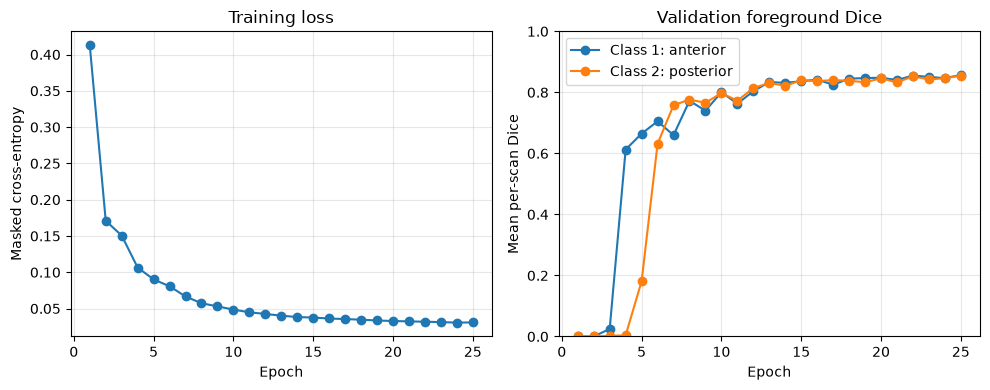

In [32]:
completed_epochs = np.arange(1, len(history["training_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(completed_epochs, history["training_loss"], marker="o")
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Masked cross-entropy")
axes[0].grid(alpha=0.3)

axes[1].plot(completed_epochs, history["anterior_dice"], marker="o", label="Class 1: anterior")
axes[1].plot(completed_epochs, history["posterior_dice"], marker="o", label="Class 2: posterior")
axes[1].set(title="Validation foreground Dice", xlabel="Epoch", ylabel="Mean per-scan Dice", ylim=(0, 1))
axes[1].grid(alpha=0.3)
axes[1].legend()
fig.tight_layout()
plt.show()

### Interpretation

This is one continued CPU training run with clear validation milestones: mean foreground Dice progressed from **0.4229 at epoch 5**, to **0.8381 at epoch 15**, and to the selected best value of **0.8559 at epoch 25**. The later epochs improved the selected validation score, but this history alone does not establish whether overfitting occurred. Checkpoint selection used validation performance; the original five-epoch checkpoint and the preserved epoch-15 checkpoint remain unchanged. No augmentation, Dice loss, alternative architecture, or extra training script was introduced.

## 12. Inspect validation predictions

We load the validation-selected `best_small_unet3d_25epochs.pt` checkpoint and evaluate all **39 validation scans**. No parameter is updated and the checkpoint is not rewritten. For each scan, we calculate anterior and posterior Dice inside `valid_region`, along with ground-truth and predicted voxel counts for both foreground classes.

The absent-class rule remains the same as during validation: if a ground-truth class is absent but predicted, its Dice is 0; if it is absent from both target and prediction, its Dice is recorded as undefined (`NaN`) and excluded from distribution summaries rather than treated as perfect.

In [33]:
inspection_checkpoint_path = Path("best_small_unet3d_25epochs.pt")
checkpoint = torch.load(inspection_checkpoint_path, map_location=device, weights_only=True)
inspection_model = SmallUNet3D(in_channels=1, num_classes=3, base_channels=8).to(device)
inspection_model.load_state_dict(checkpoint["model_state_dict"])
inspection_model.eval()
inspection_validation_loader = DataLoader(
    validation_dataset, batch_size=2, shuffle=False, num_workers=0
)

validation_results = []
with torch.no_grad():
    for inspection_batch in inspection_validation_loader:
        inspection_logits = inspection_model(inspection_batch["image"].to(device))
        inspection_predictions = inspection_logits.argmax(dim=1)
        inspection_targets = inspection_batch["mask"].to(device)
        inspection_valid = inspection_batch["valid_region"].to(device)

        for scan_index, scan_id in enumerate(inspection_batch["scan_id"]):
            prediction = inspection_predictions[scan_index][inspection_valid[scan_index]]
            target = inspection_targets[scan_index][inspection_valid[scan_index]]
            row = {"scan_id": scan_id}
            for class_id, class_name in [(1, "anterior"), (2, "posterior")]:
                predicted_class = prediction == class_id
                target_class = target == class_id
                predicted_count = int(predicted_class.sum())
                target_count = int(target_class.sum())
                if target_count == 0:
                    dice = 0.0 if predicted_count > 0 else float("nan")
                else:
                    intersection = int((predicted_class & target_class).sum())
                    dice = 2.0 * intersection / (predicted_count + target_count)
                row[f"{class_name}_dice"] = dice
                row[f"{class_name}_ground_truth_voxels"] = target_count
                row[f"{class_name}_predicted_voxels"] = predicted_count
            row["mean_foreground_dice"] = float(
                np.nanmean([row["anterior_dice"], row["posterior_dice"]])
            )
            validation_results.append(row)

assert len(validation_results) == len(validation_dataset) == 39
print(
    f"Loaded checkpoint from epoch {checkpoint['epoch']} with recorded mean foreground Dice "
    f"{checkpoint['mean_foreground_validation_dice']:.4f}."
)
print("Validation scans evaluated: 39; test scans evaluated: 0")

Loaded checkpoint from epoch 25 with recorded mean foreground Dice 0.8559.
Validation scans evaluated: 39; test scans evaluated: 0


### Score distribution and deliberately selected examples

The examples are **not presented as representative of all 39 scans**. The explicit selection rule is: (1) the lowest posterior-Dice scan, (2) the remaining scan closest to the median mean-foreground Dice, and (3) the highest mean-foreground-Dice scan not already selected. This deliberately spans weak, middle, and strong observed outcomes.

In [34]:
def distribution_summary(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    return [
        float(values.min()), float(np.percentile(values, 25)), float(np.median(values)),
        float(values.mean()), float(np.percentile(values, 75)), float(values.max()),
    ]

distribution_rows = {}
for class_name in ["anterior", "posterior"]:
    distribution_rows[class_name] = distribution_summary(
        [row[f"{class_name}_dice"] for row in validation_results]
    )

summary_lines = [
    "| Class | Minimum | Q1 | Median | Mean | Q3 | Maximum |",
    "|---|---:|---:|---:|---:|---:|---:|",
]
for class_name, values in distribution_rows.items():
    summary_lines.append(
        f"| {class_name.title()} | " + " | ".join(f"{value:.4f}" for value in values) + " |"
    )
display(Markdown("\n".join(summary_lines)))

finite_posterior = [row for row in validation_results if np.isfinite(row["posterior_dice"])]
low_posterior_case = min(finite_posterior, key=lambda row: row["posterior_dice"])
median_mean_score = float(np.median([row["mean_foreground_dice"] for row in validation_results]))
remaining_after_low = [row for row in validation_results if row["scan_id"] != low_posterior_case["scan_id"]]
median_case = min(
    remaining_after_low, key=lambda row: abs(row["mean_foreground_dice"] - median_mean_score)
)
remaining_after_two = [
    row for row in validation_results
    if row["scan_id"] not in {low_posterior_case["scan_id"], median_case["scan_id"]}
]
high_case = max(remaining_after_two, key=lambda row: row["mean_foreground_dice"])
selected_examples = [
    ("Lowest posterior Dice", low_posterior_case),
    ("Near-median mean Dice", median_case),
    ("Highest mean Dice", high_case),
]

example_lines = [
    "| Selection | Scan | Anterior Dice | Posterior Dice | GT voxels c1/c2 | Predicted voxels c1/c2 |",
    "|---|---|---:|---:|---:|---:|",
]
for selection_name, row in selected_examples:
    example_lines.append(
        f"| {selection_name} | `{row['scan_id']}` | {row['anterior_dice']:.4f} | "
        f"{row['posterior_dice']:.4f} | {row['anterior_ground_truth_voxels']:,}/"
        f"{row['posterior_ground_truth_voxels']:,} | {row['anterior_predicted_voxels']:,}/"
        f"{row['posterior_predicted_voxels']:,} |"
    )
display(Markdown("\n".join(example_lines)))

| Class | Minimum | Q1 | Median | Mean | Q3 | Maximum |
|---|---:|---:|---:|---:|---:|---:|
| Anterior | 0.7216 | 0.8482 | 0.8662 | 0.8569 | 0.8812 | 0.9174 |
| Posterior | 0.7793 | 0.8344 | 0.8571 | 0.8549 | 0.8804 | 0.9128 |

| Selection | Scan | Anterior Dice | Posterior Dice | GT voxels c1/c2 | Predicted voxels c1/c2 |
|---|---|---:|---:|---:|---:|
| Lowest posterior Dice | `hippocampus_221` | 0.7216 | 0.7793 | 1,193/1,255 | 700/1,337 |
| Near-median mean Dice | `hippocampus_070` | 0.8807 | 0.8399 | 1,895/1,555 | 1,709/1,569 |
| Highest mean Dice | `hippocampus_184` | 0.9174 | 0.9062 | 1,948/1,657 | 1,928/1,755 |

### Matching ground-truth and prediction overlays

For the lowest-posterior case, the displayed slice is the one containing the most ground-truth posterior voxels. For the other two cases, it contains the most total ground-truth foreground voxels. Both columns use the same normalized MRI slice: ground truth is overlaid on the left and the checkpoint prediction on the right.

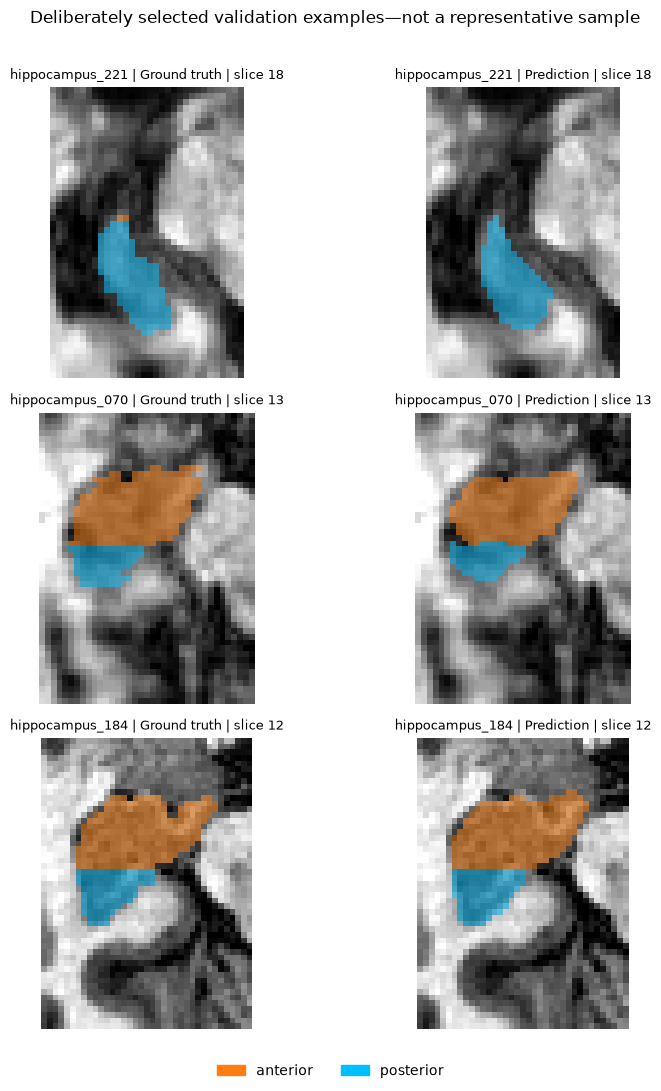

In [35]:
fig, axes = plt.subplots(3, 2, figsize=(9, 11))
selected_visual_data = []
for row_index, (selection_name, result) in enumerate(selected_examples):
    dataset_index = validation_dataset.scan_ids.index(result["scan_id"])
    item = validation_dataset[dataset_index]
    with torch.no_grad():
        prediction = inspection_model(item["image"].unsqueeze(0).to(device)).argmax(dim=1)[0]

    valid_coordinates = torch.nonzero(item["valid_region"], as_tuple=False)
    placement = tuple(
        slice(int(valid_coordinates[:, axis].min()), int(valid_coordinates[:, axis].max()) + 1)
        for axis in range(3)
    )
    image = item["image"][0][placement].numpy()
    ground_truth = item["mask"][placement].numpy()
    predicted_mask = prediction[placement].cpu().numpy()
    if selection_name == "Lowest posterior Dice":
        slice_index = int(np.argmax(np.sum(ground_truth == 2, axis=(0, 1))))
    else:
        slice_index = int(np.argmax(np.sum(ground_truth > 0, axis=(0, 1))))

    image_slice = np.rot90(image[:, :, slice_index])
    ground_truth_slice = np.rot90(ground_truth[:, :, slice_index])
    prediction_slice = np.rot90(predicted_mask[:, :, slice_index])
    for column, (overlay, label) in enumerate(
        [(ground_truth_slice, "Ground truth"), (prediction_slice, "Prediction")]
    ):
        axes[row_index, column].imshow(image_slice, cmap="gray", vmin=0, vmax=1)
        axes[row_index, column].imshow(
            np.ma.masked_equal(overlay, 0), cmap=mask_cmap, norm=mask_norm, alpha=0.5
        )
        axes[row_index, column].set_title(
            f"{result['scan_id']} | {label} | slice {slice_index}", fontsize=9
        )
        axes[row_index, column].axis("off")
    axes[row_index, 0].set_ylabel(selection_name)
    selected_visual_data.append((selection_name, result, slice_index))

fig.legend(
    handles=[Patch(color="tab:orange", label="anterior"), Patch(color="deepskyblue", label="posterior")],
    loc="lower center", ncol=2, frameon=False,
)
fig.suptitle("Deliberately selected validation examples—not a representative sample")
fig.tight_layout(rect=(0, 0.04, 1, 0.97))
plt.show()

In [36]:
posterior_ground_truth_total = sum(
    row["posterior_ground_truth_voxels"] for row in validation_results
)
posterior_predicted_total = sum(
    row["posterior_predicted_voxels"] for row in validation_results
)
if posterior_predicted_total < 0.8 * posterior_ground_truth_total:
    posterior_count_pattern = "substantially fewer posterior voxels than the ground truth, consistent with under-segmentation"
elif posterior_predicted_total > 1.2 * posterior_ground_truth_total:
    posterior_count_pattern = "substantially more posterior voxels than the ground truth, consistent with over-segmentation"
else:
    posterior_count_pattern = "a similar total number of posterior voxels, so weak overlap points more toward spatial disagreement than total volume alone"

display(Markdown(f"""
Across the 39 validation scans, the checkpoint predicts **{posterior_predicted_total:,}** posterior voxels versus **{posterior_ground_truth_total:,}** in the ground truth. It predicts {posterior_count_pattern}. The lowest-posterior example has Dice **{low_posterior_case['posterior_dice']:.4f}**, with **{low_posterior_case['posterior_predicted_voxels']:,}** predicted versus **{low_posterior_case['posterior_ground_truth_voxels']:,}** ground-truth posterior voxels.

The counts and overlays describe *how* prediction and ground truth disagree, but they cannot establish *why*. Even the completed 25-epoch run may be insufficient, and factors such as optimization, class balance, preprocessing, architecture capacity, or annotation variation would require controlled follow-up experiments. These three deliberately selected views also cannot characterize all validation scans.
"""))


Across the 39 validation scans, the checkpoint predicts **59,905** posterior voxels versus **61,861** in the ground truth. It predicts a similar total number of posterior voxels, so weak overlap points more toward spatial disagreement than total volume alone. The lowest-posterior example has Dice **0.7793**, with **1,337** predicted versus **1,255** ground-truth posterior voxels.

The counts and overlays describe *how* prediction and ground truth disagree, but they cannot establish *why*. Even the completed 25-epoch run may be insufficient, and factors such as optimization, class balance, preprocessing, architecture capacity, or annotation variation would require controlled follow-up experiments. These three deliberately selected views also cannot characterize all validation scans.


## 13. Final held-out test evaluation

The epoch-25 checkpoint was selected using validation performance and then evaluated once on the **39 held-out test scans**. The final mean per-scan Dice scores are **0.8715** for the anterior hippocampus and **0.8610** for the posterior hippocampus, giving a **0.8663 mean foreground Dice**. The test result was not used for further model or preprocessing tuning.

The split is reproducible and scan IDs do not overlap, but patient-level separation could not be verified because the available dataset identifiers do not provide confirmed patient identities. The held-out result should therefore be interpreted with that limitation in mind.

In [37]:
test_dataset = HippocampusDataset(splits["test"])
test_loader = DataLoader(
    test_dataset, batch_size=2, shuffle=False, num_workers=0
)

assert len(test_dataset) == 39
assert not (set(splits["test"]) & set(splits["train"]))
assert not (set(splits["test"]) & set(splits["validation"]))

test_device = torch.device("cpu")
test_checkpoint = torch.load(
    "best_small_unet3d_25epochs.pt",
    map_location=test_device,
    weights_only=True,
)

test_model = SmallUNet3D(
    in_channels=1, num_classes=3, base_channels=8
).to(test_device)
test_model.load_state_dict(test_checkpoint["model_state_dict"])

test_dice, test_predicted_counts, test_absent_counts = (
    validate_foreground_dice(test_model, test_loader, test_device)
)

print(f"Selected checkpoint epoch: {test_checkpoint['epoch']}")
print(f"Test scans: {len(test_dataset)}")
print(f"Anterior mean per-scan Dice: {test_dice[1]:.4f}")
print(f"Posterior mean per-scan Dice: {test_dice[2]:.4f}")
print(f"Mean foreground Dice: {np.mean([test_dice[1], test_dice[2]]):.4f}")
print(f"Predicted voxels, anterior/posterior: {test_predicted_counts[1]:,}/{test_predicted_counts[2]:,}")
print(f"Ground-truth-absent scans, anterior/posterior: {test_absent_counts[1]}/{test_absent_counts[2]}")

Selected checkpoint epoch: 25
Test scans: 39
Anterior mean per-scan Dice: 0.8715
Posterior mean per-scan Dice: 0.8610
Mean foreground Dice: 0.8663
Predicted voxels, anterior/posterior: 65,528/59,366
Ground-truth-absent scans, anterior/posterior: 0/0
